# 08 - Error analysis and report assets

This notebook turns compact experiment tables into the figures, LaTeX fragments, quantitative statements, and qualitative examples used by the report. All selections are rule-based so the report can be regenerated from saved artifacts.

**Inputs:** Aggregated metrics, tokenization results, attacked text, and selected prediction partitions.  
**Outputs:** Final PDF figures, generated LaTeX fragments, and `qualitative_examples.csv`.

## Setup and report helpers

The setup resolves artifact paths, model display names, prediction partitions, and LaTeX escaping. It does not recompute model results; this notebook is the presentation layer over the persisted analysis tables.

In [1]:
from pathlib import Path
import pandas as pd
import yaml

# Same path setup as notebook 00; repeated for independent execution.
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
CONFIG = yaml.safe_load((ROOT / 'config/experiment.yaml').read_text(encoding='utf-8'))

PATHS = {key: ROOT / value for key, value in CONFIG['paths'].items()}
for directory in (PATHS['tables'], PATHS['figures'], PATHS['report_generated'],):
    directory.mkdir(parents=True, exist_ok=True)

# Same prediction layout as notebook 03.
def prediction_partition_path(source, dataset, model, model_seed, defense):
    return PATHS['predictions'] / source / dataset / model / f'seed_{model_seed}' / f'{defense}.parquet'

def escape_latex(text):
    replacements = {'\\': r'\textbackslash{}', '&': r'\&', '%': r'\%', '$': r'\$', '#': r'\#', '_': r'\_', '{': r'\{', '}': r'\}', '~': r'\textasciitilde{}', '^': r'\textasciicircum{}'}
    return ''.join(replacements.get(ch, ch) for ch in str(text))

def write_table(filename, columns, header, rows):
    lines = [r'\begin{tabular}{' + columns + '}', r'\toprule', header, r'\midrule',
             *rows, r'\bottomrule', r'\end{tabular}']
    (PATHS['report_generated'] / filename).write_text('\n'.join(lines) + '\n', encoding='utf-8')


## Report figures

The robustness facets compare raw Macro-F1 across attack strengths, the heatmap summarizes primary-strength defense recovery, and the quartile plot relates token edit disruption to failure rate. Composition is omitted from the robustness facets because its effective coverage is negligible in these datasets.

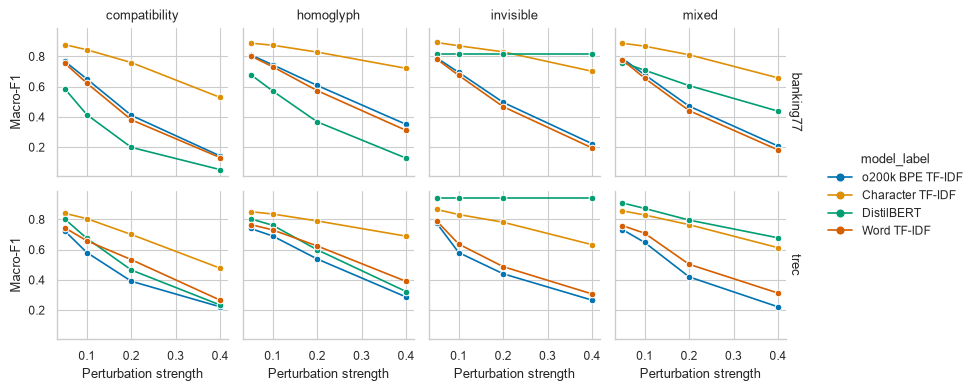

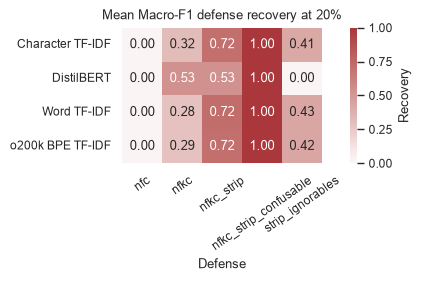

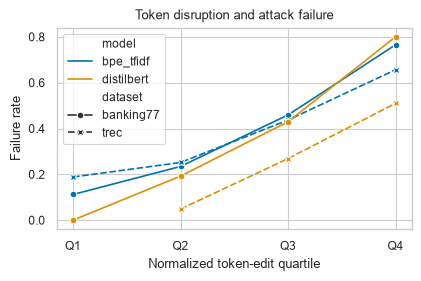

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='paper', palette='colorblind')
generated = PATHS['report_generated']
summary = pd.read_csv(PATHS['tables'] / 'metrics_summary.csv')
regression = pd.read_csv(PATHS['tables'] / 'token_failure_regression.csv')
quartiles = pd.read_csv(PATHS['tables'] / 'token_failure_quartiles.csv')
model_labels = {'word_tfidf': 'Word TF-IDF', 'char_tfidf': 'Character TF-IDF', 'bpe_tfidf': 'o200k BPE TF-IDF', 'distilbert': 'DistilBERT'}
summary['model_label'] = summary['model'].map(model_labels)

robust = summary[(summary['defense'] == 'none') & (summary['attack'].isin(['homoglyph', 'invisible', 'compatibility', 'mixed']))]
figure = sns.relplot(data=robust, x='strength', y='macro_f1_mean', hue='model_label', row='dataset', col='attack', kind='line', marker='o', height=2.0, aspect=1.05, facet_kws={'margin_titles': True})
figure.set_axis_labels('Perturbation strength', 'Macro-F1')
figure.set_titles(row_template='{row_name}', col_template='{col_name}')
figure.figure.savefig(PATHS['figures'] / 'robustness_curves.pdf', bbox_inches='tight')
plt.show()

primary = summary[(summary['attack'] != 'clean') & (summary['strength'] == CONFIG['analysis']['primary_strength']) & (summary['defense'] != 'none')]
recovery = primary.groupby(['model_label', 'defense'])['macro_f1_defense_recovery'].mean().unstack()
fig, ax = plt.subplots(figsize=(4.1, 2.7), constrained_layout=True)
sns.heatmap(recovery, annot=True, fmt='.2f', center=0, cmap='vlag', ax=ax, cbar_kws={'label': 'Recovery'})
ax.set(xlabel='Defense', ylabel='', title='Mean Macro-F1 defense recovery at 20%')
ax.tick_params(axis='x', rotation=35)
fig.savefig(PATHS['figures'] / 'defense_recovery.pdf', bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(4.1, 2.7), constrained_layout=True)
sns.lineplot(data=quartiles, x='edit_quartile', y='failure_rate', hue='model', style='dataset', markers=True, dashes=True, ax=ax)
ax.set(xlabel='Normalized token-edit quartile', ylabel='Failure rate', title='Token disruption and attack failure')
fig.savefig(PATHS['figures'] / 'token_disruption_failure.pdf', bbox_inches='tight')
plt.show()


## Tables and quantitative narrative

Clean performance, primary robustness, defense results, and attack coverage are written as LaTeX fragments. Values come directly from the saved summaries, including across-seed standard deviations where applicable. Short result sentences select extrema by explicit rules instead of manually copying numbers into the report.

The tokenization narrative reports the adjusted odds ratio and confidence interval for normalized token edit distance.

In [3]:
clean = summary[(summary['attack'] == 'clean') & (summary['defense'] == 'none')].sort_values(['dataset', 'model'])
lines = []
for row in clean.itertuples(index=False):
    accuracy = f'{row.accuracy_mean:.3f}' + (f' $\\pm$ {row.accuracy_std:.3f}' if row.accuracy_std > 0 else '')
    macro_f1 = f'{row.macro_f1_mean:.3f}' + (f' $\\pm$ {row.macro_f1_std:.3f}' if row.macro_f1_std > 0 else '')
    lines.append(f'{escape_latex(row.dataset.upper())} & {escape_latex(model_labels[row.model])} & {accuracy} & {macro_f1} \\\\')
write_table('clean_performance.tex', 'llcc', r'Dataset & Model & Accuracy & Macro-F1 \\', lines)

broad_attacks = ['homoglyph', 'invisible', 'compatibility', 'mixed']
primary_raw = summary[(summary['defense'] == 'none') & (summary['strength'] == CONFIG['analysis']['primary_strength']) & summary['attack'].isin(broad_attacks)]
primary_aggregate = primary_raw.groupby(['dataset', 'model', 'model_label'], as_index=False).agg(macro_f1=('macro_f1_mean', 'mean'), macro_f1_drop=('macro_f1_drop', 'mean'), attack_success_rate=('attack_success_rate_mean', 'mean'))
lines = []
for row in primary_aggregate.sort_values(['dataset', 'model']).itertuples(index=False):
    lines.append(f'{escape_latex(row.dataset.upper())} & {escape_latex(row.model_label)} & {row.macro_f1:.3f} & {row.macro_f1_drop:.3f} & {row.attack_success_rate:.3f} ' + r'\\')
write_table('primary_robustness.tex', 'llrrr', r'Dataset & Model & Macro-F1 & Drop & ASR \\', lines)

defense_aggregate = summary[(summary['strength'] == CONFIG['analysis']['primary_strength']) & summary['attack'].isin(broad_attacks)].groupby(['dataset', 'model', 'model_label', 'defense'], as_index=False).agg(macro_f1=('macro_f1_mean', 'mean'), recovery=('macro_f1_defense_recovery', 'mean'))
lines = []
for (dataset_name, model_name, model_label), group in defense_aggregate.groupby(['dataset', 'model', 'model_label']):
    values = group.set_index('defense')
    lines.append(f'{escape_latex(dataset_name.upper())} & {escape_latex(model_label)} & {values.loc["none", "macro_f1"]:.3f} & {values.loc["nfkc_strip", "macro_f1"]:.3f} & {values.loc["nfkc_strip", "recovery"]:.2f} & {values.loc["nfkc_strip_confusable", "macro_f1"]:.3f} ' + r'\\')
write_table('primary_defenses.tex', 'llrrrr', r'Dataset & Model & Raw & NFKC+strip & $R$ & Full repair \\', lines)

coverage = pd.read_csv(PATHS['tables'] / 'attack_coverage.csv')
coverage = coverage[coverage['strength'] == CONFIG['analysis']['primary_strength']]
lines = []
for attack_name in ['homoglyph', 'invisible', 'compatibility', 'composition', 'mixed']:
    bank = coverage[(coverage['dataset'] == 'banking77') & (coverage['attack'] == attack_name)].iloc[0]
    trec = coverage[(coverage['dataset'] == 'trec') & (coverage['attack'] == attack_name)].iloc[0]
    lines.append(f'{escape_latex(attack_name)} & {bank.coverage:.2f} & {bank.mean_changes:.2f} & {trec.coverage:.2f} & {trec.mean_changes:.2f} ' + r'\\')
write_table('attack_coverage.tex', 'lrrrr', r'Attack & B77 cov. & B77 changes & TREC cov. & TREC changes \\', lines)

narrative = []
for dataset_name, group in clean.groupby('dataset'):
    best = group.loc[group['macro_f1_mean'].idxmax()]
    narrative.append(f'On {escape_latex(dataset_name.upper())}, the best clean Macro-F1 was {best.macro_f1_mean:.3f} for {escape_latex(model_labels[best.model])}.')
raw_attacked = summary[(summary['defense'] == 'none') & (summary['attack'] != 'clean') & (summary['coverage_mean'] > 0.5)]
worst = raw_attacked.loc[raw_attacked['macro_f1_drop'].idxmax()]
narrative.append(f'The largest mean Macro-F1 drop among broadly applicable attacks was {worst.macro_f1_drop:.3f}, observed for {escape_latex(model_labels[worst.model])} under the {escape_latex(worst.attack)} attack at strength {worst.strength:.0%} on {escape_latex(worst.dataset.upper())}.')
best_recovery = primary.loc[primary['macro_f1_defense_recovery'].idxmax()]
narrative.append(f'The strongest primary-strength recovery was {best_recovery.macro_f1_defense_recovery:.2f} for {escape_latex(model_labels[best_recovery.model])} using {escape_latex(best_recovery.defense)}; recovery values are not clipped and must be read together with clean-score deltas.')
(generated / 'results_narrative.tex').write_text('\n\n'.join(narrative) + '\n', encoding='utf-8')

token_lines = []
for row in regression[regression['term'] == 'z_edit'].itertuples(index=False):
    token_lines.append(f'For {escape_latex(model_labels[row.model])}, a one-standard-deviation increase in normalized token edit distance was associated with an odds ratio of {row.odds_ratio:.2f} (95\\% CI {row.odds_ratio_ci_low:.2f}--{row.odds_ratio_ci_high:.2f}) for attack failure after controlling for dataset, attack, and strength.')
(generated / 'tokenization_narrative.tex').write_text('\n\n'.join(token_lines) + '\n', encoding='utf-8')
clean[['dataset', 'model', 'accuracy_mean', 'accuracy_std', 'macro_f1_mean', 'macro_f1_std']]


,dataset,model,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std
4,banking77,bpe_tfidf,0.882143,0.000000,0.882234,0.000000
130,banking77,char_tfidf,0.905844,0.000000,0.905900,0.000000
256,banking77,distilbert,0.831818,0.002886,0.818726,0.004005
382,banking77,word_tfidf,0.885390,0.000000,0.885686,0.000000
508,trec,bpe_tfidf,0.890000,0.000000,0.878803,0.000000
634,trec,char_tfidf,0.888000,0.000000,0.883020,0.000000
760,trec,distilbert,0.966667,0.003055,0.944463,0.008850
886,trec,word_tfidf,0.888000,0.000000,0.884534,0.000000


## Qualitative error cases

The target model-dataset pair is chosen by the highest mixed-attack success rate at the primary strength. Within that target, examples represent the largest successful confidence drop, strongest defense recovery, and strongest resisted perturbation. Non-ASCII and invisible code points are rendered explicitly for auditability.

In [4]:
def ascii_audit(text, limit=105):
    rendered = ''.join(ch if 32 <= ord(ch) < 127 else f'[U+{ord(ch):04X}]' for ch in text)
    return rendered if len(rendered) <= limit else rendered[:limit - 3] + '...'

target_metric = raw_attacked[(raw_attacked['strength'] == CONFIG['analysis']['primary_strength']) & (raw_attacked['attack'] == 'mixed')].sort_values('attack_success_rate_mean', ascending=False).iloc[0]
target_model, target_dataset = target_metric['model'], target_metric['dataset']
target_seed = CONFIG['transformer']['seeds'][0] if target_model == 'distilbert' else CONFIG['project']['root_seed']
raw_path = prediction_partition_path('raw', target_dataset, target_model, int(target_seed), 'none')
defense_path = prediction_partition_path('defense', target_dataset, target_model, int(target_seed), 'nfkc_strip_confusable')
raw_frame = pd.read_parquet(raw_path)
defense_frame = pd.read_parquet(defense_path)
clean_probability = raw_frame[raw_frame['attack'] == 'clean'][['example_id', 'gold_probability', 'correct']].rename(columns={'gold_probability': 'clean_probability', 'correct': 'clean_correct'})
attacked = raw_frame[(raw_frame['attack_seed'] == 13) & (raw_frame['strength'] == CONFIG['analysis']['primary_strength'])].merge(clean_probability, on='example_id', validate='many_to_one')
attacked['probability_drop'] = attacked['clean_probability'] - attacked['gold_probability']
defended = defense_frame[(defense_frame['attack_seed'] == 13) & (defense_frame['strength'] == CONFIG['analysis']['primary_strength'])][['example_id', 'attack', 'gold_probability', 'correct']].rename(columns={'gold_probability': 'defended_probability', 'correct': 'defended_correct'})
attacked = attacked.merge(defended, on=['example_id', 'attack'], validate='one_to_one')
attack_texts = pd.read_parquet(PATHS['attacks'])
attack_texts = attack_texts[(attack_texts['dataset'] == target_dataset) & (attack_texts['attack_seed'] == 13) & (attack_texts['strength'] == CONFIG['analysis']['primary_strength'])][['example_id', 'attack', 'clean_text', 'attacked_text']]
attacked = attacked.merge(attack_texts, on=['example_id', 'attack'], validate='one_to_one')
success = attacked[attacked['clean_correct'] & ~attacked['correct']].nlargest(1, 'probability_drop').assign(case='Successful attack')
recovered_pool = attacked[attacked['clean_correct'] & ~attacked['correct'] & attacked['defended_correct']].copy()
recovered_pool['recovery_gain'] = recovered_pool['defended_probability'] - recovered_pool['gold_probability']
recovered = recovered_pool.nlargest(1, 'recovery_gain').assign(case='Recovered by defense') if len(recovered_pool) else attacked.nlargest(1, 'defended_probability').assign(case='Highest defended score')
resisted = attacked[attacked['clean_correct'] & attacked['correct']].nlargest(1, 'probability_drop').assign(case='Prediction resisted')
examples = pd.concat([success, recovered, resisted], ignore_index=True)
examples.to_csv(PATHS['tables'] / 'qualitative_examples.csv', index=False)
lines = [r'\begin{table*}[t]', r'\centering', r'\scriptsize', r'\caption{Rule-selected examples; non-ASCII and invisible code points are shown explicitly.}', r'\begin{tabularx}{\textwidth}{@{}llllX@{}}', r'\toprule', r'Case & Dataset & Model & Attack & Auditable text \\', r'\midrule']
for row in examples.itertuples(index=False):
    text = f'clean: {ascii_audit(row.clean_text)}; attacked: {ascii_audit(row.attacked_text)}'
    lines.append(f'{escape_latex(row.case)} & {escape_latex(row.dataset.upper())} & {escape_latex(model_labels[row.model])} & {escape_latex(row.attack)} & {escape_latex(text)} \\\\')
lines.extend([r'\bottomrule', r'\end{tabularx}', r'\label{tab:errors}', r'\end{table*}'])
(generated / 'error_examples.tex').write_text('\n'.join(lines) + '\n', encoding='utf-8')
examples[['case', 'dataset', 'model', 'attack', 'probability_drop', 'defended_probability']]


,case,dataset,model,attack,probability_drop,defended_probability
0,Successful attack,banking77,word_tfidf,homoglyph,0.998486,0.999152
1,Recovered by defense,banking77,word_tfidf,homoglyph,0.998486,0.999152
2,Prediction resisted,banking77,word_tfidf,invisible,0.955857,0.997920


## Interpretation

The examples illustrate mechanisms already visible in aggregate metrics; they do not replace those metrics. Rule-based selection reduces manual cherry-picking, while explicit code-point rendering prevents visually hidden changes from being mistaken for identical strings.